# EuroSAT land-use classification with a CNN

EuroSAT: 27 000 Sentinel-2 RGB patches (64×64 px), 10 classes – forest, river, highway,
industrial, residential, annual crop, etc.

A small CNN trained from scratch, with data augmentation. Run on Google Colab (GPU).

In [1]:
import io
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

tf.random.set_seed(42)

In [2]:
# course zip next to the notebook (on Colab: upload it to /content). It holds EuroSAT.zip inside.
DATA_DIR = Path("eurosat_data/2750")   # one sub-folder per class

if not DATA_DIR.exists():
    course_zip = next(Path(".").glob("Group A*Eurosat*.zip"))
    with zipfile.ZipFile(course_zip) as outer:
        inner = next(n for n in outer.namelist() if n.endswith("EuroSAT.zip"))
        with zipfile.ZipFile(io.BytesIO(outer.read(inner))) as z:
            z.extractall("eurosat_data")

IMG = 64
BATCH = 64

# validation_split + same seed keeps the two subsets disjoint
train_ds, val_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="both", seed=42,
    image_size=(IMG, IMG), batch_size=BATCH)

class_names = train_ds.class_names
print(class_names)

Found 27000 files belonging to 10 classes.


Using 21600 files for training.


Using 5400 files for validation.


['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


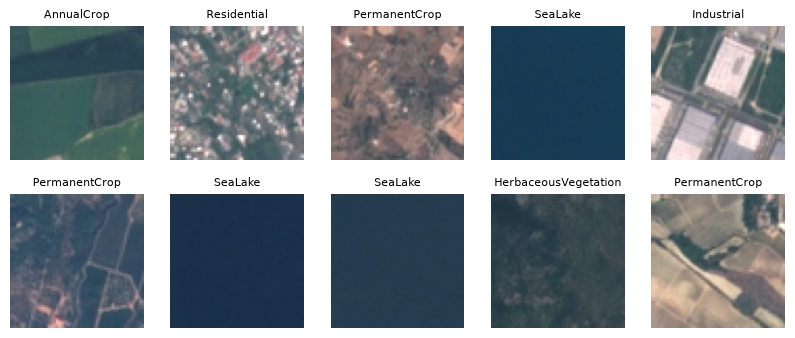

In [3]:
plt.figure(figsize=(10, 4))
for imgs, labels in train_ds.take(1):
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=8)
        plt.axis("off")
plt.show()

In [4]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

## Model

Augmentation lives inside the model so it's only active during training (and isn't frozen by `.cache()`).
Satellite images have no "up", so vertical flips and 90° rotations are all valid.

BatchNorm uses momentum 0.9 instead of the default 0.99: with the default, the running statistics
lagged behind the weights and validation accuracy jumped between ~50 % and ~80 % from epoch to epoch.

In [5]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.1),
])

model = keras.Sequential([
    layers.Input(shape=(IMG, IMG, 3)),
    augment,
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation="softmax"),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,434 (372.79 KB)

 Trainable params: 94,986 (371.04 KB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=callbacks, verbose=2)

Epoch 1/40


C:\Users\advai\tfenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


338/338 - 165s - 487ms/step - accuracy: 0.6302 - loss: 1.0504 - val_accuracy: 0.7333 - val_loss: 0.7701 - learning_rate: 0.0010


Epoch 2/40


338/338 - 121s - 359ms/step - accuracy: 0.7463 - loss: 0.7210 - val_accuracy: 0.4756 - val_loss: 1.9621 - learning_rate: 0.0010


Epoch 3/40


... (49 outputs left out)

Epoch 28/40


338/338 - 149s - 441ms/step - accuracy: 0.9391 - loss: 0.1859 - val_accuracy: 0.8987 - val_loss: 0.2909 - learning_rate: 3.1250e-05


Epoch 29/40


338/338 - 176s - 521ms/step - accuracy: 0.9388 - loss: 0.1851 - val_accuracy: 0.8870 - val_loss: 0.3172 - learning_rate: 1.5625e-05


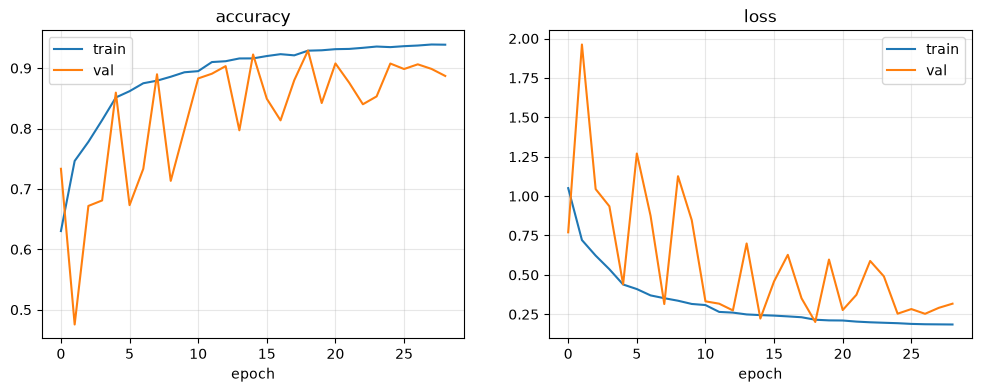

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, key in zip(ax, ["accuracy", "loss"]):
    a.plot(history.history[key], label="train")
    a.plot(history.history["val_" + key], label="val")
    a.set_title(key); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.show()

## Evaluation

In [8]:
y_true = np.concatenate([y for _, y in val_ds])
y_pred = model.predict(val_ds, verbose=0).argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

                      precision    recall  f1-score   support

          AnnualCrop      0.962     0.888     0.923       597
              Forest      0.982     0.985     0.983       600
HerbaceousVegetation      0.934     0.833     0.880       557
             Highway      0.967     0.838     0.898       493
          Industrial      0.961     0.924     0.942       512
             Pasture      0.902     0.965     0.933       374
       PermanentCrop      0.821     0.941     0.877       491
         Residential      0.859     1.000     0.924       607
               River      0.923     0.920     0.921       547
             SeaLake      0.995     0.986     0.990       622

            accuracy                          0.929      5400
           macro avg      0.931     0.928     0.927      5400
        weighted avg      0.933     0.929     0.929      5400



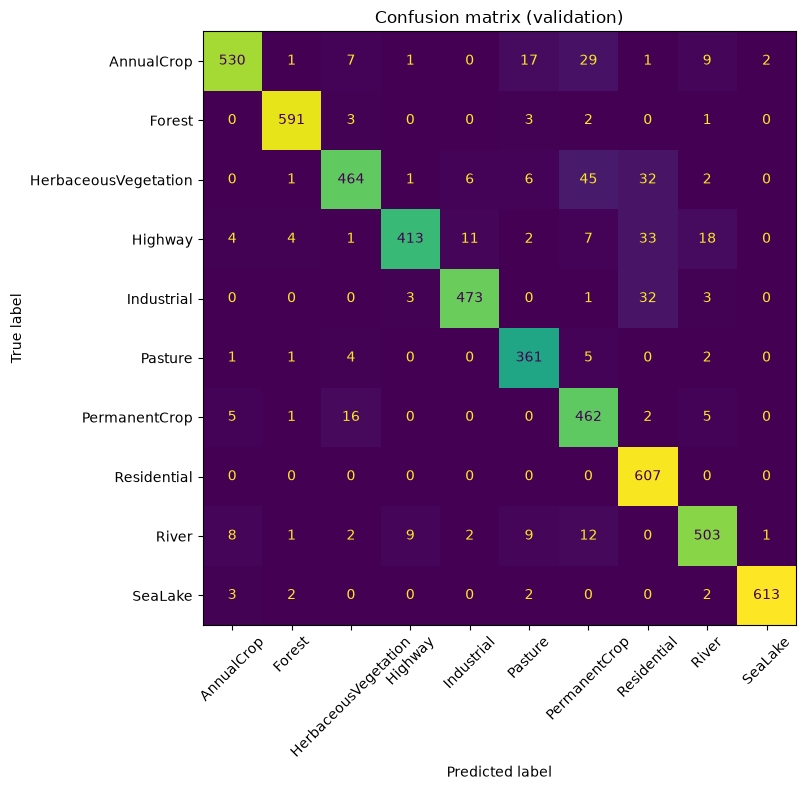

In [9]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix (validation)")
plt.tight_layout(); plt.show()

Most confusion is between the vegetation classes (permanent crop, herbaceous vegetation, pasture),
which look alike from above. Highway has the lowest recall. The next step would be transfer learning
(e.g. a pretrained ResNet/EfficientNet), which typically pushes EuroSAT accuracy above 95 %.